# **Image color analysis**

Install first required modules:

```bash
pip install scikit-learn
pip install rembg
pip install "rembg[cpu]"
```

#### **1. Histogram of pixels**

Histograms show the distribution of pixel intensities.
- For grayscale images: histogram shows count of pixel intensities (0–255).
- For color images: analyze each channel separately, otherwise the result is a sum of channel intensities, without distinguishing colors.

Basic histogram of all pixels in any image (flattened):

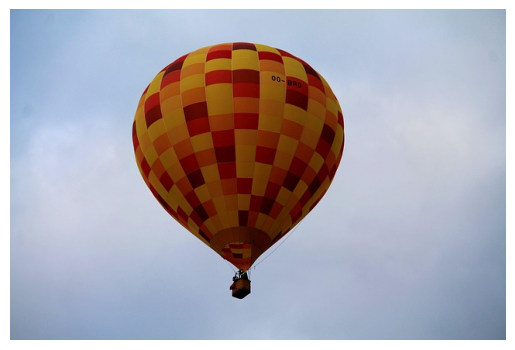

In [20]:
import matplotlib.pyplot as plt
from skimage import io

# image = io.imread('caffee.jpg') 
image = io.imread('baloon2.jpg') 

plt.imshow(image)
plt.axis('off')
plt.show()

In [21]:
type(image)

numpy.ndarray

In [22]:
image.shape

(427, 640, 3)

In [23]:
image_raveled = image.ravel()
image_raveled.shape

(819840,)

In [24]:
image.shape[0] * image.shape[1] * image.shape[2] 

819840

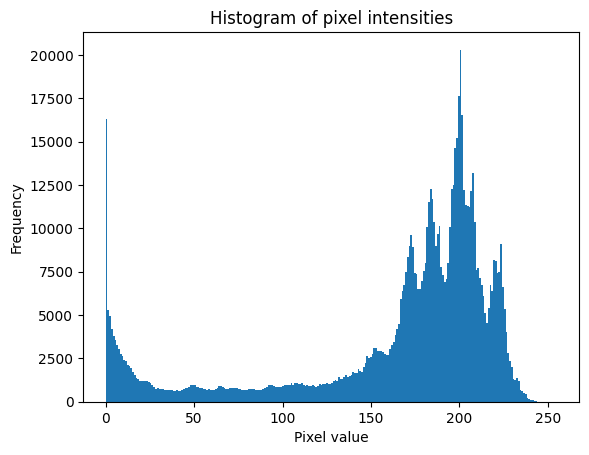

In [25]:
plt.hist(image.ravel(), bins=256, range=(0, 255))
plt.title("Histogram of pixel intensities")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()

- `img_skimage.ravel()` converts the image array into a 1D array of pixel values.
- `bins=256` corresponds to all possible values for 8-bit images.

#### **2. Color channel histograms**

Using `skimage.exposure.histogram`, compute histograms for R, G, and B channels separately.

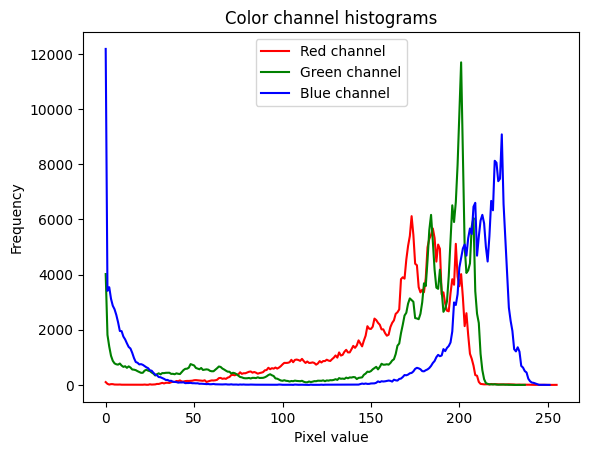

In [26]:
from skimage.exposure import histogram

r_hist, r_centers = histogram(image[:, :, 0])
g_hist, g_centers = histogram(image[:, :, 1])
b_hist, b_centers = histogram(image[:, :, 2])

plt.plot(r_centers, r_hist, color='red', label='Red channel')
plt.plot(g_centers, g_hist, color='green', label='Green channel')
plt.plot(b_centers, b_hist, color='blue', label='Blue channel')
plt.title("Color channel histograms")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

#### **3. Extract dominant colors - color quantization with KMeans**


Use `sklearn.cluster.KMeans` to find dominant colors (color quantization).

In [27]:
from sklearn.cluster import KMeans
import numpy as np

# reshape the image to a 2D array of pixels (num_pixels, 3)
pixels = image.reshape(-1, 3)

print(pixels.shape)

(273280, 3)


In [28]:
# run KMeans clustering to find 5 dominant colors
kmeans = KMeans(n_clusters=5, random_state=42).fit(pixels)
kmeans


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [29]:
# extract cluster centers (RGB colors)
dominant_colors = kmeans.cluster_centers_.astype(int)

print("Dominant colors (RGB):")
for i, color in enumerate(dominant_colors):
    print(f"Color {i+1}: {color}")


Dominant colors (RGB):
Color 1: [190 201 220]
Color 2: [138  76  17]
Color 3: [88 19  3]
Color 4: [140 158 185]
Color 5: [167 181 205]


Dominant colors summarize image appearance for applications like compression or image search.
Let's display palette of dominant colors, generated for our picture.

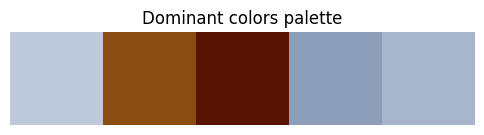

In [30]:
import matplotlib.patches as patches

fig, ax = plt.subplots(1, 1, figsize=(6, 2))

for i, color in enumerate(dominant_colors):
    rect = patches.Rectangle((i, 0), 1, 1, facecolor=np.array(color)/255)
    ax.add_patch(rect)

ax.set_xlim(0, len(dominant_colors))
ax.set_ylim(0, 1)
ax.axis('off')
plt.title("Dominant colors palette")
ax.set_aspect('equal')
plt.show()

# Removing background

Removing background - method 1 - use only when the foreground and background have strong contrast

(np.float64(-0.5), np.float64(639.5), np.float64(426.5), np.float64(-0.5))

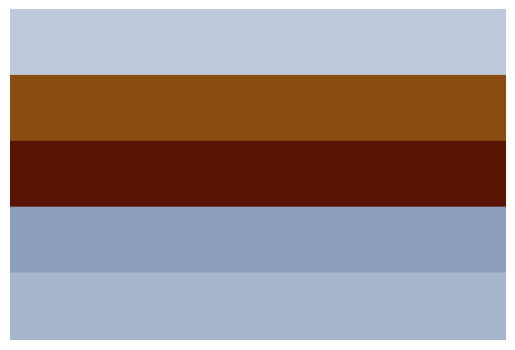

In [31]:
# 1 - Get size of original image
height, width, channels = image.shape

# 2 - Create a new background using the dominant colors - stripes of the dominant colors
# 2.A - empty background
background = np.zeros((height, width, channels), dtype=np.uint8)

# 2.B - calculate width of each stripe
num_colors = len(dominant_colors)
stripe_width = width // num_colors
stripe_height = height // num_colors

# 2.C - draw stripes of dominant colors
for i, color in enumerate(dominant_colors):
    start_y = i * stripe_height
    end_y = (i + 1) * stripe_height if i < num_colors - 1 else height
    background[start_y:end_y, :] = color

plt.imshow(background)
plt.axis('off')    

(np.float64(-0.5), np.float64(639.5), np.float64(426.5), np.float64(-0.5))

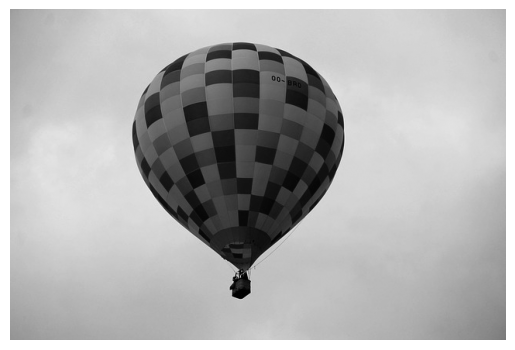

In [32]:
# 3 - remove background in original image
# Convert to grascale to see better the difference between foreground and background
from skimage.color import rgb2gray
gray_image = rgb2gray(image)

plt.imshow(gray_image, cmap='gray')
plt.axis('off')

(np.float64(-0.5), np.float64(639.5), np.float64(426.5), np.float64(-0.5))

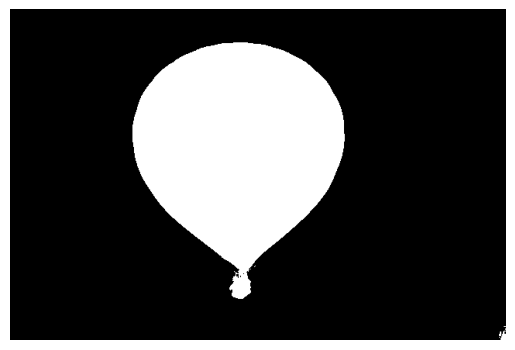

In [46]:
# Create a mask where the foreground is white - (True) and background is black - (False). The treshold is something we need to guess.
# image_mask = gray_image > 0.50
image_mask = gray_image < 0.57

plt.imshow(image_mask, cmap='gray')
plt.axis('off')

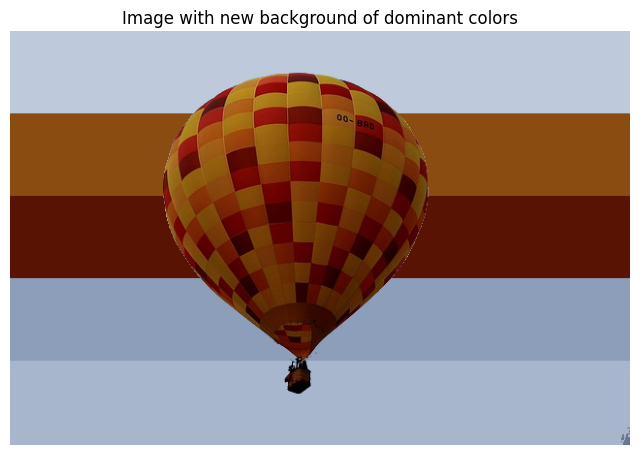

In [47]:

# 4 - COMBINING THE ORIGINAL IMAGE WITH THE NEW BACKGROUND ---
# Create a copy of the background, on which we will "paste" the original image
final_image = background.copy()

# Take pixels from the original cat image where the mask is True (cat area) and put them on the final image
final_image[image_mask] = image[image_mask]

# 5 - Display the final image
plt.figure(figsize=(8, 6))
plt.imshow(final_image)
plt.axis('off')
plt.title("Image with new background of dominant colors")
plt.show()

Better methods to get the right foreground/background (but idea still the same)

Isolating the original image from the background... Please wait.


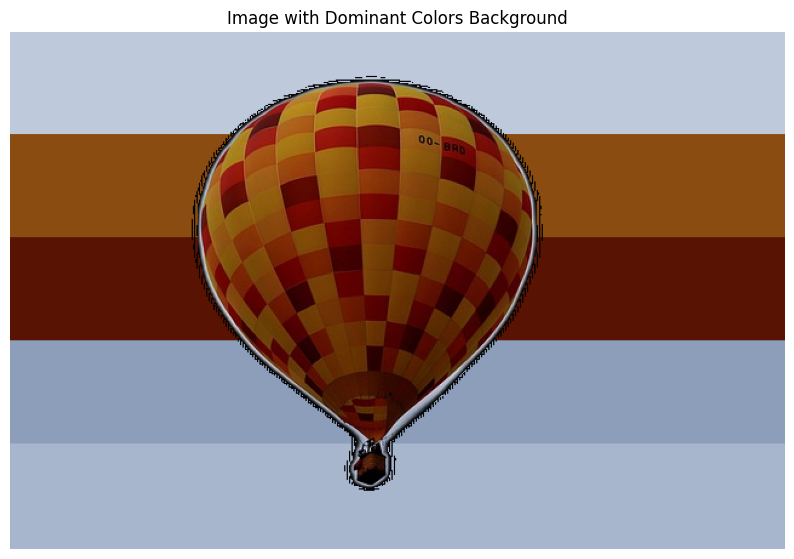

In [48]:
from rembg import remove

# 4. ISOLATE THE ORIGINAL IMAGE USING AI (REMBG) 
# rembg automatically detects the foreground object and returns an RGBA image
# where the background is completely transparent (Alpha channel = 0)
print("Isolating the original image from the background... Please wait.")
rgba_image = remove(image)

# Extract the RGB channels and the Alpha (transparency) mask
image_rgb = rgba_image[:, :, :3]
alpha_mask = rgba_image[:, :, 3]

# Create a boolean mask where the original image is present (Alpha > 0)
image_presence_mask = alpha_mask > 0

# 5. COMBINE THE ORIGINAL IMAGE WITH THE NEW BACKGROUND 
final_image = background.copy()

# Paste the isolated cat onto the new striped background
final_image[image_presence_mask] = image_rgb[image_presence_mask]

# 6. DISPLAY AND SAVE THE RESULT
plt.figure(figsize=(10, 8))
plt.imshow(final_image)
plt.axis('off')
plt.title("Image with Dominant Colors Background")
plt.show()


Use aliasing on edges

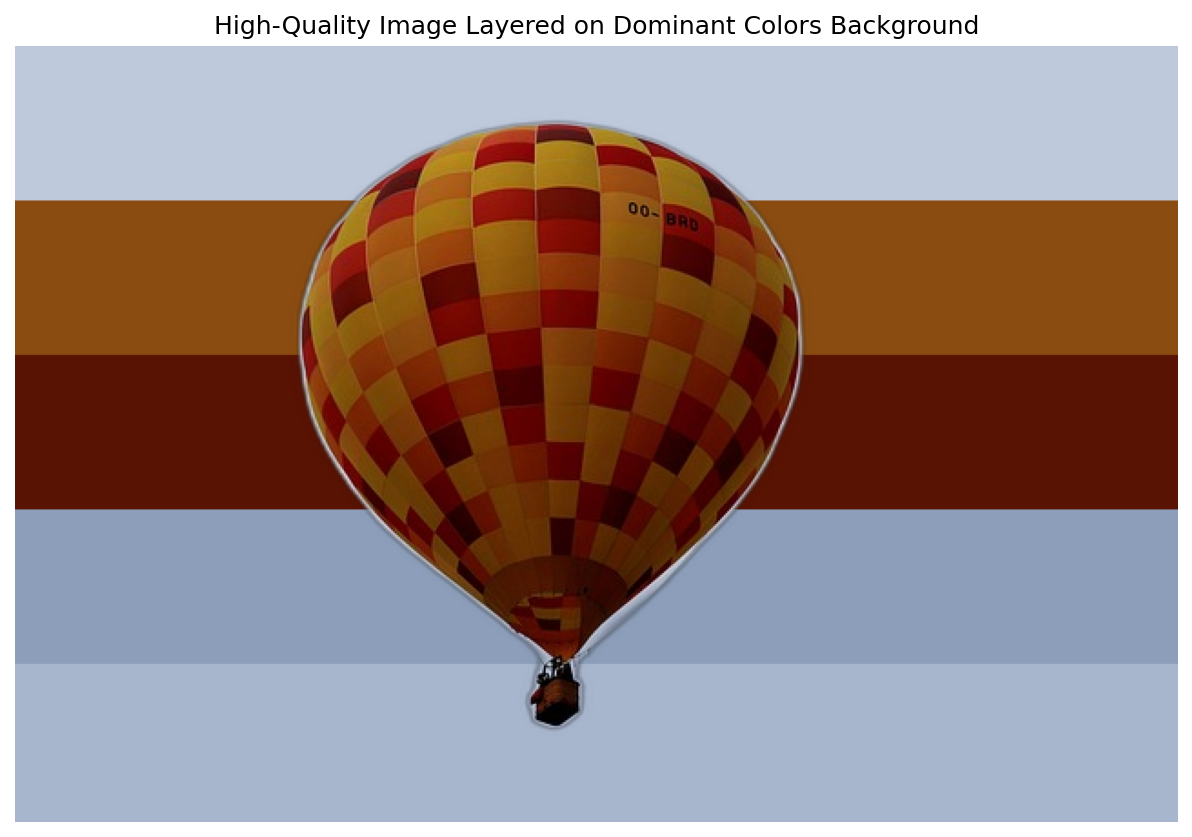

In [49]:
# Extract RGB channels of the original image and the smooth Alpha mask (values from 0.0 to 1.0)
image_rgb = rgba_image[:, :, :3].astype(float)
alpha_mask = (rgba_image[:, :, 3] / 255.0).reshape(height, width, 1)

# --- 5. SMOOTH ALPHA BLENDING (PHOTOSHOP-LIKE MERGE) ---
# Formula: Final = (Cat * Alpha) + (Background * (1 - Alpha))
background_float = background.astype(float)

final_image_float = (image_rgb * alpha_mask) + (background_float * (1.0 - alpha_mask))
final_image = final_image_float.astype(np.uint8)

# --- 6. DISPLAY AND SAVE THE PREMIUM RESULT ---
plt.figure(figsize=(10, 8), dpi=150)
plt.imshow(final_image)
plt.axis('off')
plt.title("High-Quality Image Layered on Dominant Colors Background")
plt.show()



#### **4. Extracting RGB channels**

Extract individual red, green, and blue channels from the image to analyze channel-specific content. Display them using different colormaps for clearer interpretation.

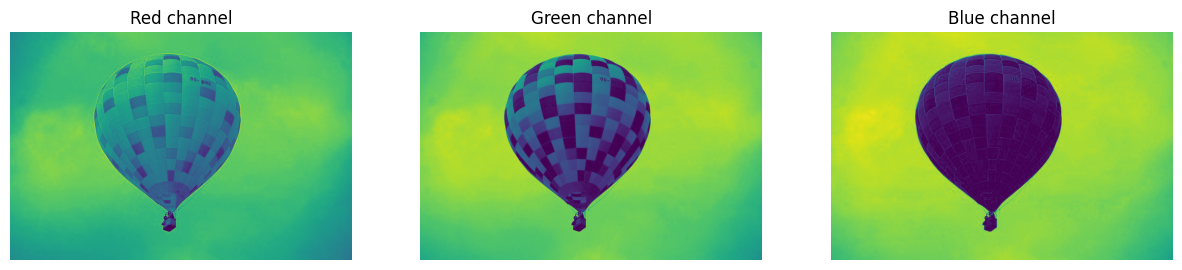

In [50]:
red_channel = image[:, :, 0]
green_channel = image[:, :, 1]
blue_channel = image[:, :, 2]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(red_channel)
axs[0].set_title('Red channel')
axs[0].axis('off')

axs[1].imshow(green_channel)
axs[1].set_title('Green channel')
axs[1].axis('off')

axs[2].imshow(blue_channel)
axs[2].set_title('Blue channel')
axs[2].axis('off')

plt.show()

Let's try the simplest background removal using the right channel

(np.float64(-0.5), np.float64(639.5), np.float64(426.5), np.float64(-0.5))

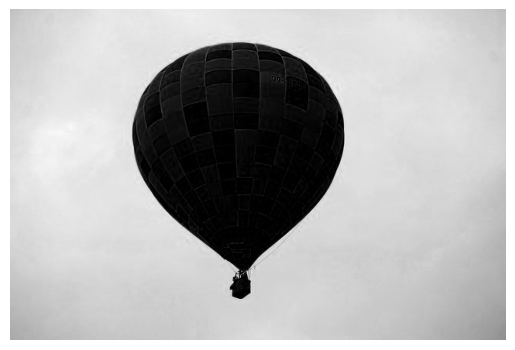

In [51]:
# gray_image = red_channel / 255
gray_image = blue_channel / 255

plt.imshow(gray_image, cmap='gray')
plt.axis('off')

(np.float64(-0.5), np.float64(639.5), np.float64(426.5), np.float64(-0.5))

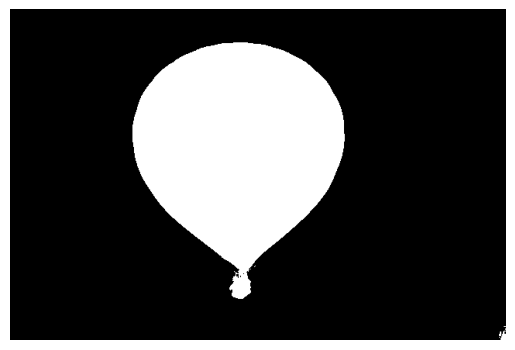

In [52]:
# image_mask = gray_image > 0.6
image_mask = gray_image < 0.57

plt.imshow(image_mask, cmap='gray')
plt.axis('off')

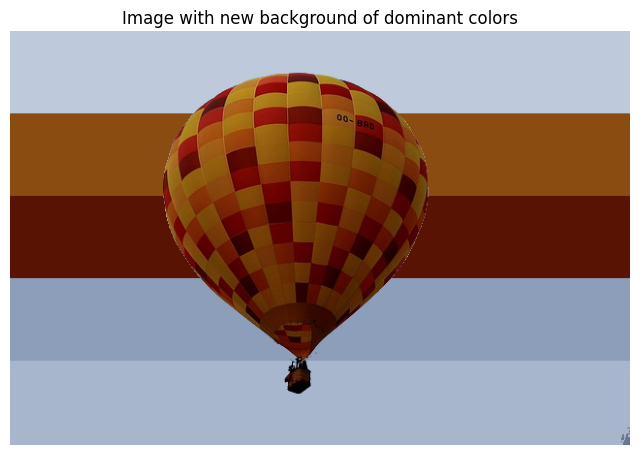

In [53]:

final_image = background.copy()
final_image[image_mask] = image[image_mask]

plt.figure(figsize=(8, 6))
plt.imshow(final_image)
plt.axis('off')
plt.title("Image with new background of dominant colors")
plt.show()

Channels in gray

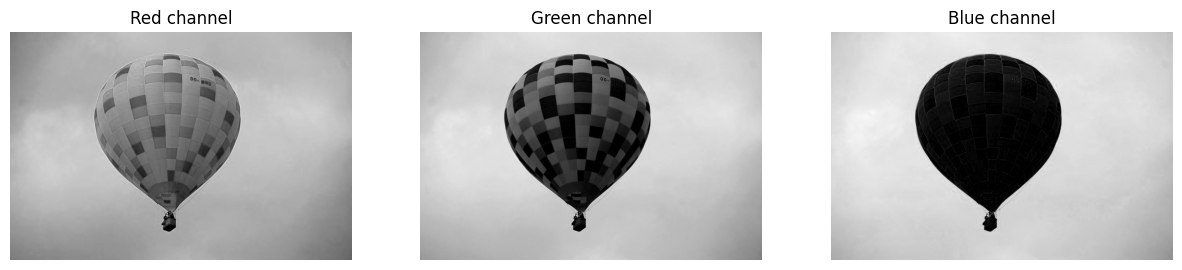

In [54]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(red_channel, cmap="gray")
axs[0].set_title('Red channel')
axs[0].axis('off')

axs[1].imshow(green_channel, cmap="gray")
axs[1].set_title('Green channel')
axs[1].axis('off')

axs[2].imshow(blue_channel, cmap="gray")
axs[2].set_title('Blue channel')
axs[2].axis('off')

plt.show()

Channels in colors

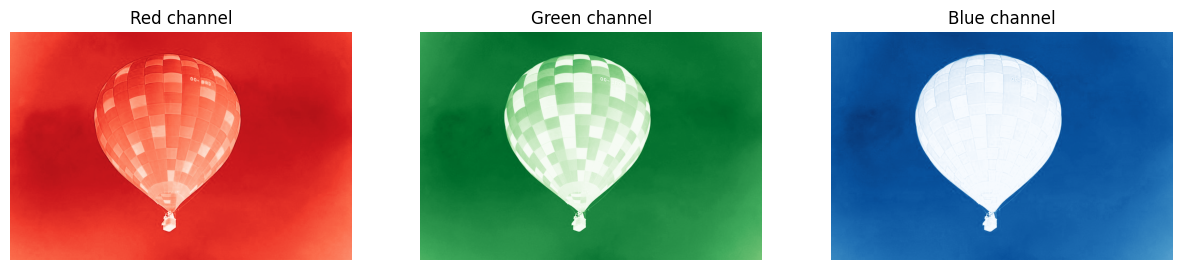

In [55]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(red_channel, cmap="Reds")
axs[0].set_title('Red channel')
axs[0].axis('off')

axs[1].imshow(green_channel, cmap="Greens")
axs[1].set_title('Green channel')
axs[1].axis('off')

axs[2].imshow(blue_channel, cmap="Blues")
axs[2].set_title('Blue channel')
axs[2].axis('off')

plt.show()

#### **5. Color intensity heatmaps**

Heatmaps visualize intensity distribution within each channel to identify prominent regions. 

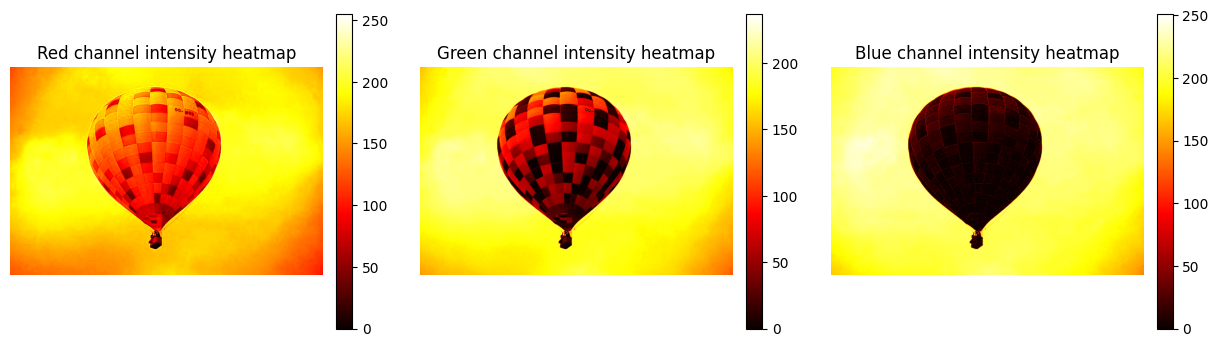

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
channels = ['Red', 'Green', 'Blue']

for i, ax in enumerate(axes):
    im = ax.imshow(image[:, :, i], cmap='hot')
    ax.set_title(f"{channels[i]} channel intensity heatmap")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.show()

#### **6. Convert and visualize images in different color spaces**

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.24608261303048193..1.0].


(np.float64(-0.5), np.float64(639.5), np.float64(426.5), np.float64(-0.5))

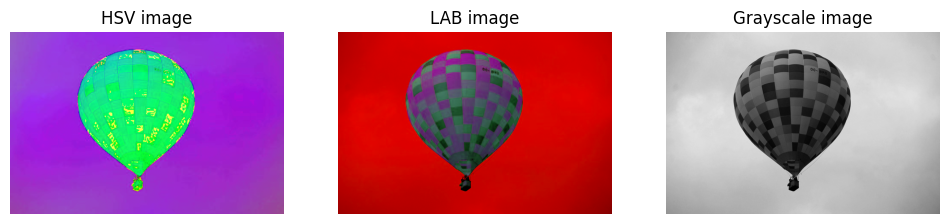

In [57]:
from skimage import color

hsv = color.rgb2hsv(image)
lab = color.rgb2lab(image)
gray = color.rgb2gray(image)

plt.figure(figsize=(12, 3))

plt.subplot(1, 3, 1)
plt.imshow(hsv)
plt.title("HSV image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lab / np.max(lab), cmap='viridis')  # scaled for visualization
plt.title("LAB image")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale image")
plt.axis('off')

#### **7. Image segmentation based on dominant color clusters**

Using KMeans labels, segment the image according to dominant color clusters. Each pixel is assigned to a color cluster representing a segment.

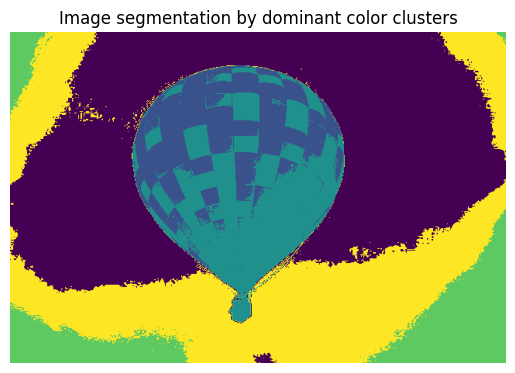

In [58]:
labels = kmeans.labels_.reshape(image.shape[0], image.shape[1])
plt.imshow(labels, cmap='viridis')
plt.title("Image segmentation by dominant color clusters")
plt.axis('off')
plt.show()